# Model Notebook
### Emotion Classification – Base Models + Stacking Ensemble

**Prerequisites:** Run `notebooks/preprocess.ipynb` first to generate `datasets/processed/`.

**Flow:**
1. Load processed data & config, set up grid search
2. Base model A – **Naive Bayes** (TF-IDF + MultinomialNB) – grid search → final fit
3. Base model B – **SVM** (TF-IDF + LinearSVC w/ calibration) – grid search → final fit
4. Base model C – **XGBoost** (TF-IDF + XGBClassifier) – grid search → final fit
5. **Stacking Ensemble** (out-of-fold from the *tuned* base models → tuned Logistic Regression meta-learner)
6. All models saved to `models/`

## 1. Load Processed Data & Configuration

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from sklearn.preprocessing import LabelEncoder

# ---- Load config written by preprocess.ipynb ----
PROCESSED_DIR = os.path.join("../datasets", "processed")
with open(os.path.join(PROCESSED_DIR, "config.json")) as f:
    cfg = json.load(f)

EMOTION_LABELS = cfg["EMOTION_LABELS"]
N_FOLDS        = cfg["N_FOLDS"]
SEED           = cfg["SEED"]
K              = cfg["K"]
MODELS_DIR     = cfg["MODELS_DIR"]

os.makedirs(MODELS_DIR, exist_ok=True)

# ---- Load arrays ----
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"), allow_pickle=True)
X_test  = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"),  allow_pickle=True)
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
y_test  = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))
classes = np.load(os.path.join(PROCESSED_DIR, "label_encoder_classes.npy"), allow_pickle=True)

le = LabelEncoder()
le.classes_ = classes

print(f"Train: {len(X_train):,}  |  Test: {len(X_test):,}")
print(f"Classes ({K}):", list(le.classes_))
print(f"Emotion labels: {EMOTION_LABELS}")
print(f"N_FOLDS={N_FOLDS}  SEED={SEED}  MODELS_DIR='{MODELS_DIR}'")

Train: 800  |  Test: 200
Classes (3): [np.str_('anger'), np.str_('fear'), np.str_('sadness')]
Emotion labels: ['anger', 'fear', 'sadness']
N_FOLDS=5  SEED=42  MODELS_DIR='../models'


## 1b. Grid-Search Setup

* One shared helper (`run_grid_search`) is used for every model below.
* Tuning only sees `X_train` (stratified CV). The test set is untouched until final evaluation.
* Set `RUN_GRID_SEARCH = False` to skip the search and re-use `models/best_params.json` from the last run.
* `REFIT = "f1_macro"` because the classes are imbalanced (anger ~64%). Switch to `"accuracy"` if that is what you want to optimise.

In [2]:
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold

# ---- Grid-search settings ----
RUN_GRID_SEARCH = True                       # False -> re-use models/best_params.json
SCORING   = {"accuracy": "accuracy", "f1_macro": "f1_macro"}
REFIT     = "f1_macro"                       # metric used to pick the winner
GS_CV     = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
GS_N_JOBS = -1                               # parallel over candidates (each model itself is single-threaded)
BEST_PARAMS_PATH = os.path.join(MODELS_DIR, "best_params.json")

TUNING = {}   # key -> {"params": {...}, "cv_accuracy": float, "cv_f1_macro": float}
if not RUN_GRID_SEARCH and os.path.exists(BEST_PARAMS_PATH):
    with open(BEST_PARAMS_PATH) as f:
        TUNING = json.load(f)
    for v in TUNING.values():   # JSON turns tuples into lists; sklearn wants tuples for ngram_range
        v["params"] = {k: tuple(x) if k.endswith("ngram_range") else x for k, x in v["params"].items()}


def run_grid_search(key, label, estimator, grid, X=None, y=None):
    """Exhaustive grid search with stratified CV on the training data only."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    if not RUN_GRID_SEARCH:
        if key not in TUNING:
            raise RuntimeError(f"No cached params for '{key}' - set RUN_GRID_SEARCH = True")
        print(f"[{label}] cached best params: {TUNING[key]['params']}")
        return None

    n = len(ParameterGrid(grid))
    print(f"[{label}] {n} combinations x {N_FOLDS} folds = {n * N_FOLDS} fits")
    gs = GridSearchCV(estimator, grid, scoring=SCORING, refit=REFIT, cv=GS_CV,
                      n_jobs=GS_N_JOBS, error_score="raise")
    gs.fit(X, y)

    b = gs.best_index_
    TUNING[key] = {
        "params":      gs.best_params_,
        "cv_accuracy": float(gs.cv_results_["mean_test_accuracy"][b]),
        "cv_f1_macro": float(gs.cv_results_["mean_test_f1_macro"][b]),
    }
    with open(BEST_PARAMS_PATH, "w") as f:
        json.dump(TUNING, f, indent=2)

    res = pd.DataFrame(gs.cv_results_).sort_values(f"rank_test_{REFIT}").head(5)
    cols = [c for c in res.columns if c.startswith("param_")] + [
        "mean_test_accuracy", "mean_test_f1_macro", "std_test_f1_macro"]
    print(f"[{label}] best {REFIT} (CV) = {TUNING[key]['cv_f1_macro']:.4f}"
          f"  | accuracy (CV) = {TUNING[key]['cv_accuracy']:.4f}")
    print(f"[{label}] best params: {gs.best_params_}")
    display(res[cols].round(4).reset_index(drop=True))
    return gs


def apply_best(estimator, key):
    """Return `estimator` configured with the tuned params for `key` (if any)."""
    if key in TUNING:
        estimator.set_params(**TUNING[key]["params"])
    return estimator

print(f"Grid search: {'ON' if RUN_GRID_SEARCH else 'OFF (cached)'} | refit on {REFIT} | CV = {N_FOLDS}-fold stratified")

Grid search: ON | refit on f1_macro | CV = 5-fold stratified


## Helper – Confusion Matrix Plotter

In [3]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix", figsize=(8, 6)):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(K)))
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.colorbar(im, ax=ax)
    ax.set(xticks=range(K), yticks=range(K),
           xticklabels=le.classes_, yticklabels=le.classes_,
           xlabel="Predicted label", ylabel="True label",
           title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}",
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.show()


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1-macro : {f1:.4f}")
    print()
    print(classification_report(y_true, y_pred,
                                 target_names=le.classes_,
                                 zero_division=0))
    plot_confusion_matrix(y_true, y_pred, title=f"Confusion Matrix – {name}")

print("Helper functions ready.")

Helper functions ready.


## Data Exploration & Word Clouds

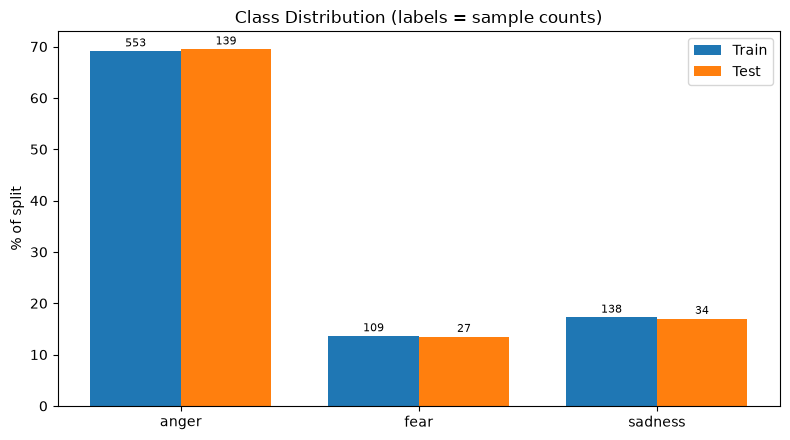

In [4]:
import os
import pandas as pd
from collections import Counter
from wordcloud import WordCloud, STOPWORDS

FIG_DIR = os.path.join("figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

CLASS_NAMES = [str(c) for c in le.classes_]
texts_train = [str(t) for t in X_train]
texts_test  = [str(t) for t in X_test]

# Add your own stop-words here (e.g. Indonesian ones) if the clouds are dominated by filler words
EXTRA_STOPWORDS = set()
STOP = set(STOPWORDS) | EXTRA_STOPWORDS

# ---- Class distribution (train vs test) ----
train_counts = np.bincount(y_train, minlength=K)
test_counts  = np.bincount(y_test,  minlength=K)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(K); w = 0.38
b1 = ax.bar(x - w/2, train_counts / train_counts.sum() * 100, w, label="Train")
b2 = ax.bar(x + w/2, test_counts  / test_counts.sum()  * 100, w, label="Test")
for bars, cnt in ((b1, train_counts), (b2, test_counts)):
    for rect, c in zip(bars, cnt):
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.4, str(c),
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("% of split"); ax.set_title("Class Distribution (labels = sample counts)")
ax.legend(); plt.tight_layout(); save_fig("class_distribution"); plt.show()

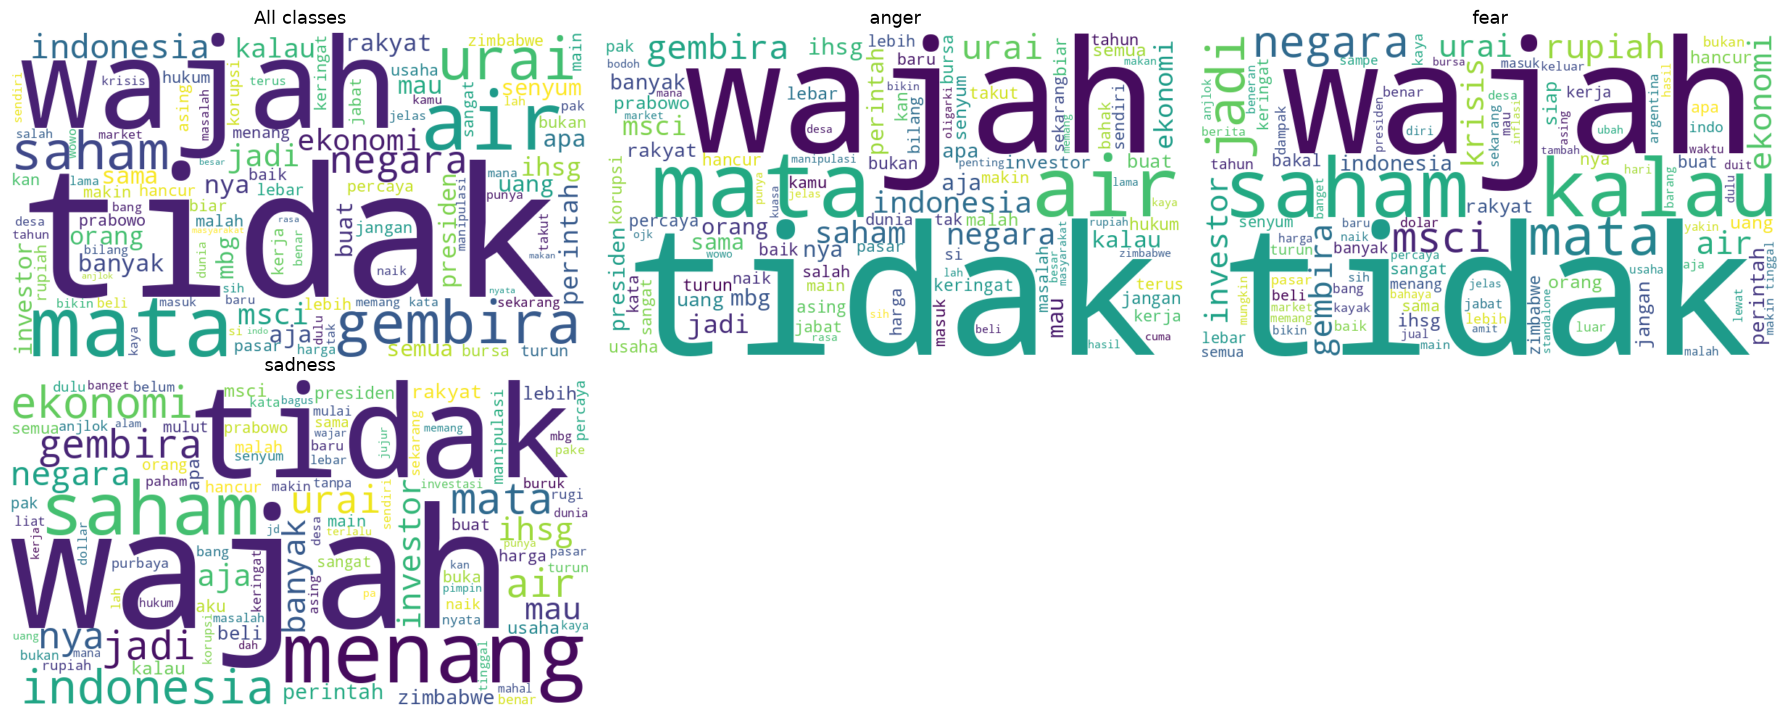

In [5]:
# ---- Word cloud per class + overall ----
def make_cloud(text):
    if not text.strip():
        return None
    return WordCloud(width=800, height=450, background_color="white",
                     stopwords=STOP, collocations=False, max_words=100,
                     random_state=SEED).generate(text)

panels = [("All classes", " ".join(texts_train))] + [
    (name, " ".join(t for t, y in zip(texts_train, y_train) if y == i))
    for i, name in enumerate(CLASS_NAMES)
]

ncols = 3
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, (title, text) in zip(axes.ravel(), panels):
    wc = make_cloud(text)
    if wc is not None:
        ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=13); ax.axis("off")
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
plt.tight_layout(); save_fig("wordclouds_per_class"); plt.show()

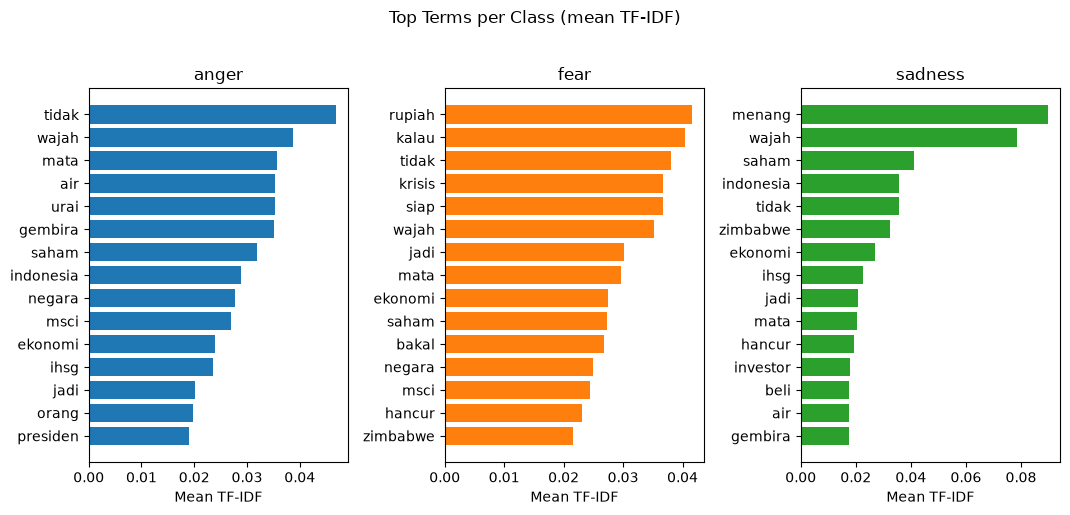

In [6]:
# ---- Top-15 terms per class by mean TF-IDF (replaces the manual Counter / raw-frequency count) ----
# Each term is scored by its average TF-IDF weight over the training documents of that class, so words that are
# frequent in a class but also common everywhere (low IDF) are pushed down automatically.
TOP_N = 15
eda_tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w{3,}\b", sublinear_tf=True)   # same len > 2 rule as before
Xt_eda    = eda_tfidf.fit_transform(texts_train)
eda_vocab = np.array(eda_tfidf.get_feature_names_out())
keep      = np.array([w not in STOP for w in eda_vocab])                          # drop wordcloud stop-words

fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 5), sharex=False)
for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), CLASS_NAMES)):
    mean_tfidf = np.asarray(Xt_eda[y_train == i].mean(axis=0)).ravel()
    mean_tfidf[~keep] = 0
    top = np.argsort(mean_tfidf)[::-1][:TOP_N]
    ax.barh(eda_vocab[top][::-1], mean_tfidf[top][::-1], color=f"C{i}")
    ax.set_title(name); ax.set_xlabel("Mean TF-IDF")
plt.suptitle("Top Terms per Class (mean TF-IDF)", y=1.02)
plt.tight_layout(); save_fig("top_words_per_class"); plt.show()

## 2. Base Model A – Naive Bayes

### 2.1 Grid search

In [7]:
from sklearn.naive_bayes import MultinomialNB

def _nb_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   MultinomialNB(alpha=0.5)),
    ])

NB_GRID = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df":      [1, 2, 3, 5],
    "clf__alpha":         [0.05, 0.1, 0.3, 0.5, 1.0, 2.0],
    "clf__fit_prior":     [True, False],     # False = uniform class prior (helps minority classes)
}
gs_nb = run_grid_search("nb", "Naive Bayes", _nb_base(), NB_GRID)

[Naive Bayes] 96 combinations x 5 folds = 480 fits
[Naive Bayes] best f1_macro (CV) = 0.5843  | accuracy (CV) = 0.7312
[Naive Bayes] best params: {'clf__alpha': 2.0, 'clf__fit_prior': False, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}


,param_clf__alpha,param_clf__fit_prior,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,2.0,False,5,"(1, 2)",0.7312,0.5843,0.0381
1,0.3,False,3,"(1, 2)",0.6975,0.5767,0.0304
2,0.3,False,2,"(1, 2)",0.7438,0.5725,0.0461
3,1.0,False,5,"(1, 2)",0.6888,0.5722,0.0294
4,1.0,False,3,"(1, 1)",0.7362,0.5721,0.0262


### 2.2 Final model (best params, evaluated on the test set)

Naive Bayes model saved to '../models/naive_bayes.pkl'
=== Naive Bayes ===
Accuracy : 0.7100
F1-macro : 0.5241

              precision    recall  f1-score   support

       anger       0.78      0.88      0.83       139
        fear       0.48      0.37      0.42        27
     sadness       0.43      0.26      0.33        34

    accuracy                           0.71       200
   macro avg       0.56      0.51      0.52       200
weighted avg       0.68      0.71      0.69       200



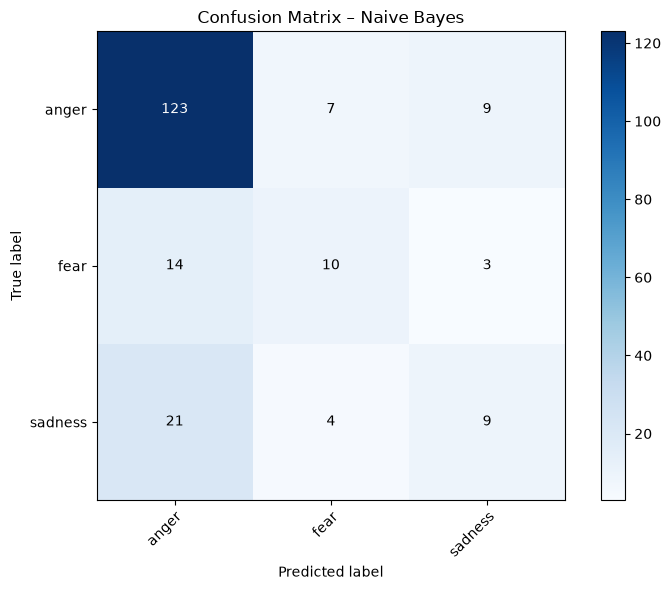

In [8]:
import joblib

def make_nb():
    return apply_best(_nb_base(), "nb")     # tuned params from the grid search above

nb_model = make_nb()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

# Save
nb_path = os.path.join(MODELS_DIR, "naive_bayes.pkl")
joblib.dump(nb_model, nb_path)
print(f"Naive Bayes model saved to '{nb_path}'")

evaluate("Naive Bayes", y_test, y_pred_nb)

## 3. Base Model B – SVM

### 3.1 Grid search

In [9]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

def _svm_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        # random_state: LinearSVC (liblinear) shuffles data internally -> unseeded = different result every run
        ("clf",   CalibratedClassifierCV(
                      LinearSVC(class_weight="balanced", random_state=SEED, max_iter=10000), cv=3)),
    ])

SVM_GRID = {
    "tfidf__ngram_range":        [(1, 1), (1, 2)],
    "tfidf__min_df":             [1, 2],
    "clf__estimator__C":         [0.1, 0.3, 1, 3, 10],
    "clf__estimator__class_weight": [None, "balanced"],
}
gs_svm = run_grid_search("svm", "SVM", _svm_base(), SVM_GRID)

[SVM] 40 combinations x 5 folds = 200 fits
[SVM] best f1_macro (CV) = 0.5973  | accuracy (CV) = 0.7737
[SVM] best params: {'clf__estimator__C': 1, 'clf__estimator__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


,param_clf__estimator__C,param_clf__estimator__class_weight,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,1.0,balanced,1,"(1, 2)",0.7737,0.5973,0.0439
1,1.0,NaN,1,"(1, 2)",0.7737,0.5973,0.0439
2,3.0,NaN,1,"(1, 2)",0.7675,0.5901,0.0370
3,3.0,balanced,1,"(1, 2)",0.7675,0.5901,0.0370
4,10.0,balanced,1,"(1, 2)",0.7662,0.5891,0.0375


### 3.2 Final model (best params, evaluated on the test set)

SVM model saved to '../models/svm.pkl'
=== SVM ===
Accuracy : 0.7450
F1-macro : 0.5669

              precision    recall  f1-score   support

       anger       0.77      0.93      0.84       139
        fear       0.53      0.37      0.43        27
     sadness       0.77      0.29      0.43        34

    accuracy                           0.74       200
   macro avg       0.69      0.53      0.57       200
weighted avg       0.74      0.74      0.72       200



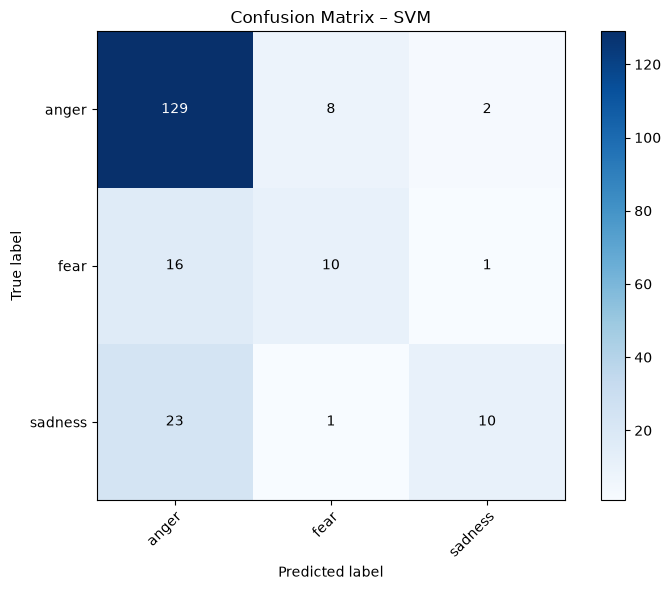

In [10]:
def make_svm():
    return apply_best(_svm_base(), "svm")   # tuned params from the grid search above

svm_model = make_svm()
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

# Save
svm_path = os.path.join(MODELS_DIR, "svm.pkl")
joblib.dump(svm_model, svm_path)
print(f"SVM model saved to '{svm_path}'")

evaluate("SVM", y_test, y_pred_svm)

## 4. Base Model C – XGBoost

### 4.1 Grid search

In [11]:
from xgboost import XGBClassifier

def _xgb_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=1,          # multi-threaded float reductions can change results; GridSearchCV parallelises instead
        )),
    ])

XGB_GRID = {
    "clf__n_estimators":     [100, 300, 500],
    "clf__learning_rate":    [0.05, 0.1],
    "clf__max_depth":        [2, 3, 6],
    "clf__colsample_bytree": [0.5, 1.0],
}
gs_xgb = run_grid_search("xgb", "XGBoost", _xgb_base(), XGB_GRID)

[XGBoost] 36 combinations x 5 folds = 180 fits
[XGBoost] best f1_macro (CV) = 0.5621  | accuracy (CV) = 0.7500
[XGBoost] best params: {'clf__colsample_bytree': 0.5, 'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 500}


,param_clf__colsample_bytree,param_clf__learning_rate,param_clf__max_depth,param_clf__n_estimators,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,0.5,0.10,6,500,0.7500,0.5621,0.0473
1,1.0,0.05,6,300,0.7612,0.5621,0.0311
2,1.0,0.10,6,300,0.7475,0.5559,0.0440
3,0.5,0.05,6,500,0.7512,0.5541,0.0409
4,0.5,0.10,6,300,0.7488,0.5539,0.0449


### 4.2 Final model (best params, evaluated on the test set)

XGBoost model saved to '../models/xgboost.pkl'
=== XGBoost ===
Accuracy : 0.7050
F1-macro : 0.4952

              precision    recall  f1-score   support

       anger       0.76      0.90      0.83       139
        fear       0.47      0.26      0.33        27
     sadness       0.43      0.26      0.33        34

    accuracy                           0.70       200
   macro avg       0.55      0.47      0.50       200
weighted avg       0.67      0.70      0.67       200



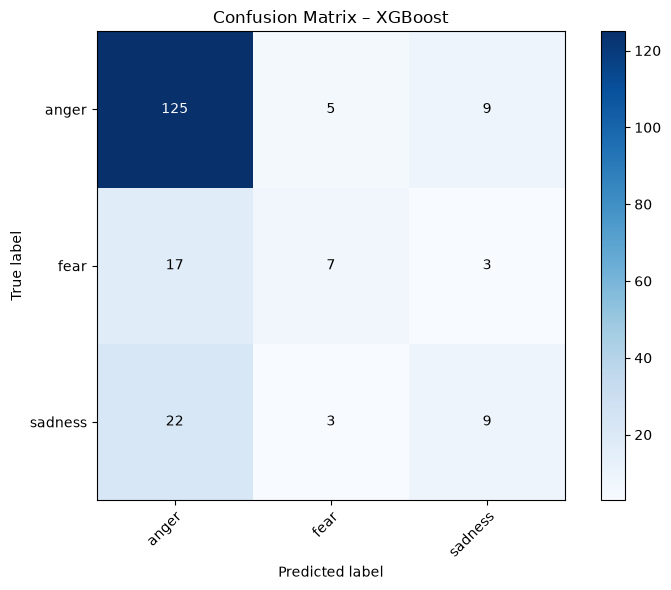

In [12]:
def make_xgb():
    return apply_best(_xgb_base(), "xgb")   # tuned params from the grid search above

xgb_model = make_xgb()
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

# Save
xgb_path = os.path.join(MODELS_DIR, "xgboost.pkl")
joblib.dump(xgb_model, xgb_path)
print(f"XGBoost model saved to '{xgb_path}'")

evaluate("XGBoost", y_test, y_pred_xgb)

## 5. Stacking Ensemble

**Strategy:** Out-of-fold (OOF) predictions from the three base models become
features for a Logistic Regression meta-learner.  This avoids data leakage
because each training fold's predictions are made by a model that never saw
those samples during training.

```
              [NB proba] [SVM proba] [XGB proba]
                         ↓
              Logistic Regression (meta-learner)
                         ↓
                  Emotion prediction
```

### 5.1 Generate Out-of-Fold Predictions

In [13]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
n_train = len(X_train)

oof = {
    "nb":  np.zeros((n_train, K)),
    "svm": np.zeros((n_train, K)),
    "xgb": np.zeros((n_train, K)),
}

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"Fold {fold}/{N_FOLDS}")
    Xtr, Xva = X_train[tr_idx], X_train[va_idx]
    ytr = y_train[tr_idx]

    nb_f  = make_nb().fit(Xtr, ytr)
    svm_f = make_svm().fit(Xtr, ytr)
    xgb_f = make_xgb().fit(Xtr, ytr)

    oof["nb"][va_idx]  = nb_f.predict_proba(Xva)
    oof["svm"][va_idx] = svm_f.predict_proba(Xva)
    oof["xgb"][va_idx] = xgb_f.predict_proba(Xva)

print("OOF prediction complete.")

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
OOF prediction complete.


### 5.2 Tune & Train Meta-Learner

In [14]:
from sklearn.linear_model import LogisticRegression

meta_train = np.hstack([oof["nb"], oof["svm"], oof["xgb"]])

# Tune the meta-learner on the out-of-fold features (CV over rows of meta_train)
META_GRID = {
    "C":            [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"],
}
gs_meta = run_grid_search("meta", "Meta-learner (LogReg)",
                          LogisticRegression(max_iter=2000, random_state=SEED),
                          META_GRID, X=meta_train, y=y_train)

meta_learner = apply_best(LogisticRegression(max_iter=2000, random_state=SEED), "meta")
meta_learner.fit(meta_train, y_train)
print("Meta-learner (Logistic Regression) trained with:", TUNING.get("meta", {}).get("params", "defaults"))

[Meta-learner (LogReg)] 10 combinations x 5 folds = 50 fits
[Meta-learner (LogReg)] best f1_macro (CV) = 0.5988  | accuracy (CV) = 0.7350
[Meta-learner (LogReg)] best params: {'C': 0.01, 'class_weight': 'balanced'}


,param_C,param_class_weight,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,0.01,balanced,0.7350,0.5988,0.0175
1,0.10,balanced,0.7200,0.5954,0.0194
2,1.00,NaN,0.7688,0.5854,0.0254
3,1.00,balanced,0.6912,0.5785,0.0253
4,10.00,NaN,0.7612,0.5725,0.0346


Meta-learner (Logistic Regression) trained with: {'C': 0.01, 'class_weight': 'balanced'}


### 5.3 Evaluate Stacking Ensemble on Test Set

=== Stacking Ensemble (NB + SVM + XGBoost) ===
Accuracy : 0.7250
F1-macro : 0.6007

              precision    recall  f1-score   support

       anger       0.83      0.83      0.83       139
        fear       0.45      0.48      0.46        27
     sadness       0.52      0.50      0.51        34

    accuracy                           0.72       200
   macro avg       0.60      0.60      0.60       200
weighted avg       0.73      0.72      0.73       200



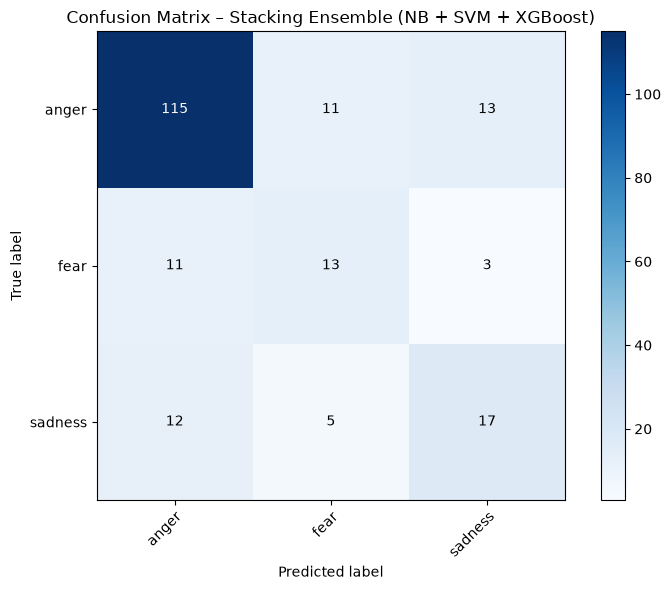

In [15]:
# Generate test-set probabilities from each base model (trained on full train set)
p_nb  = nb_model.predict_proba(X_test)
p_svm = svm_model.predict_proba(X_test)
p_xgb = xgb_model.predict_proba(X_test)

meta_test  = np.hstack([p_nb, p_svm, p_xgb])
y_pred_ens = meta_learner.predict(meta_test)

evaluate("Stacking Ensemble (NB + SVM + XGBoost)", y_test, y_pred_ens)

## 6. Save All Models

In [16]:
# Base models were already saved individually above.
# Save the meta-learner.
meta_path = os.path.join(MODELS_DIR, "meta_learner.pkl")
joblib.dump(meta_learner, meta_path)

# Save the label-encoder classes so inference code can reconstruct it
le_path = os.path.join(MODELS_DIR, "label_encoder_classes.npy")
np.save(le_path, le.classes_)

print("All models saved:")
for fname in ["naive_bayes.pkl", "svm.pkl", "xgboost.pkl",
              "meta_learner.pkl", "label_encoder_classes.npy"]:
    fpath = os.path.join(MODELS_DIR, fname)
    size  = os.path.getsize(fpath) / 1024
    print(f"  {fpath}  ({size:.1f} KB)")

All models saved:
  ../models/naive_bayes.pkl  (58.0 KB)
  ../models/svm.pkl  (1948.1 KB)
  ../models/xgboost.pkl  (1902.6 KB)
  ../models/meta_learner.pkl  (1.1 KB)
  ../models/label_encoder_classes.npy  (0.2 KB)


## 7. Summary Comparison

In [17]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score, log_loss, precision_recall_fscore_support,
)

# prediction + class probabilities for every model (Ensemble probabilities come from the meta-learner)
model_outputs = {
    "Naive Bayes": (y_pred_nb,  nb_model.predict_proba(X_test)),
    "SVM":         (y_pred_svm, svm_model.predict_proba(X_test)),
    "XGBoost":     (y_pred_xgb, xgb_model.predict_proba(X_test)),
    "Ensemble":    (y_pred_ens, meta_learner.predict_proba(meta_test)),
}

# ---- Overall metrics ----
results = []
for name, (y_pred, y_proba) in model_outputs.items():
    results.append({
        "Model":              name,
        "Accuracy":           accuracy_score(y_test, y_pred),
        "Balanced Acc":       balanced_accuracy_score(y_test, y_pred),
        "Precision (macro)":  precision_score(y_test, y_pred, average="macro",    zero_division=0),
        "Recall (macro)":     recall_score(y_test,    y_pred, average="macro",    zero_division=0),
        "F1 (macro)":         f1_score(y_test,        y_pred, average="macro",    zero_division=0),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)":    recall_score(y_test,    y_pred, average="weighted", zero_division=0),
        "F1 (weighted)":        f1_score(y_test,        y_pred, average="weighted", zero_division=0),
        "Cohen Kappa":        cohen_kappa_score(y_test, y_pred),
        "MCC":                matthews_corrcoef(y_test, y_pred),
        "ROC-AUC (OvR)":      roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
        "Log Loss":           log_loss(y_test, y_proba, labels=list(range(K))),
    })

summary = pd.DataFrame(results).set_index("Model").round(4)
print("Overall metrics (test set)")
display(summary)

# best model per metric (lower is better only for Log Loss)
best = {c: (summary[c].idxmin() if c == "Log Loss" else summary[c].idxmax()) for c in summary.columns}
print("Best model per metric:")
display(pd.Series(best, name="Best model").to_frame().T)

# ---- Per-class precision / recall / F1 ----
rows = {}
for name, (y_pred, _) in model_outputs.items():
    p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=list(range(K)), zero_division=0)
    rows[name] = {(cls, m): v
                  for cls, pv, rv, fv in zip(CLASS_NAMES, p, r, f)
                  for m, v in (("Precision", pv), ("Recall", rv), ("F1", fv))}
per_class_summary = pd.DataFrame(rows).T.round(4)
per_class_summary.columns = pd.MultiIndex.from_tuples(per_class_summary.columns)
print("Per-class metrics (test set)")
display(per_class_summary)

Overall metrics (test set)


,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Cohen Kappa,MCC,ROC-AUC (OvR),Log Loss
Model,,,,,,,,,,,,
Naive Bayes,0.710,0.5067,0.5611,0.5067,0.5241,0.6782,0.710,0.6875,0.3078,0.3162,0.7710,0.8149
SVM,0.745,0.5308,0.6878,0.5308,0.5669,0.7355,0.745,0.7151,0.3500,0.3778,0.8227,0.6112
XGBoost,0.705,0.4744,0.5525,0.4744,0.4952,0.6656,0.705,0.6741,0.2664,0.2803,0.7580,0.8373
Ensemble,0.725,0.6029,0.5989,0.6029,0.6007,0.7273,0.725,0.7260,0.4184,0.4185,0.8154,0.9588


Best model per metric:


,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Cohen Kappa,MCC,ROC-AUC (OvR),Log Loss
Best model,SVM,Ensemble,SVM,Ensemble,Ensemble,SVM,SVM,Ensemble,Ensemble,Ensemble,SVM,SVM


Per-class metrics (test set)


anger                      fear                   sadness  \
            Precision  Recall      F1 Precision  Recall      F1 Precision   
Naive Bayes    0.7785  0.8849  0.8283    0.4762  0.3704  0.4167    0.4286   
SVM            0.7679  0.9281  0.8404    0.5263  0.3704  0.4348    0.7692   
XGBoost        0.7622  0.8993  0.8251    0.4667  0.2593  0.3333    0.4286   
Ensemble       0.8333  0.8273  0.8303    0.4483  0.4815  0.4643    0.5152   

                             
             Recall      F1  
Naive Bayes  0.2647  0.3273  
SVM          0.2941  0.4255  
XGBoost      0.2647  0.3273  
Ensemble     0.5000  0.5075

## 8. Output Analysis & Visualizations

Everything below uses the already-trained models and test-set predictions. Figures are also saved to `figures/`.

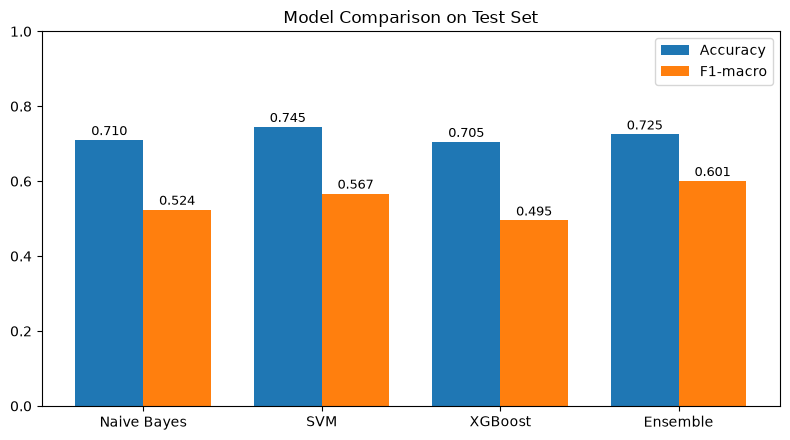

In [18]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

preds = {
    "Naive Bayes": y_pred_nb,
    "SVM":         y_pred_svm,
    "XGBoost":     y_pred_xgb,
    "Ensemble":    y_pred_ens,
}
proba_ens = meta_learner.predict_proba(meta_test)
y_test_bin = label_binarize(y_test, classes=list(range(K)))

# ---- 8.1 Overall model comparison ----
acc = [accuracy_score(y_test, p) for p in preds.values()]
f1m = [f1_score(y_test, p, average="macro", zero_division=0) for p in preds.values()]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(preds)); w = 0.38
r1 = ax.bar(x - w/2, acc, w, label="Accuracy")
r2 = ax.bar(x + w/2, f1m, w, label="F1-macro")
for r in list(r1) + list(r2):
    ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.005, f"{r.get_height():.3f}",
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(preds.keys()); ax.set_ylim(0, 1)
ax.set_title("Model Comparison on Test Set"); ax.legend()
plt.tight_layout(); save_fig("model_comparison"); plt.show()

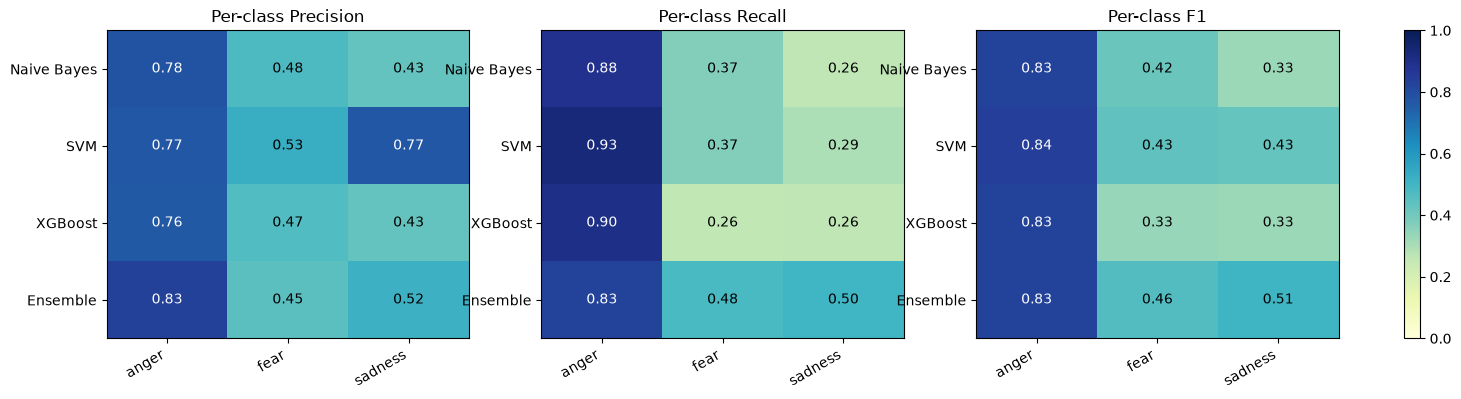

In [19]:
# ---- 8.2 Per-class F1 / precision / recall heatmaps ----
metrics = {"Precision": 0, "Recall": 1, "F1": 2}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (mname, midx) in zip(axes, metrics.items()):
    mat = np.array([
        precision_recall_fscore_support(y_test, p, labels=list(range(K)), zero_division=0)[midx]
        for p in preds.values()
    ])
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(len(preds))); ax.set_yticklabels(preds.keys())
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                    color="white" if mat[i, j] > 0.6 else "black")
    ax.set_title(f"Per-class {mname}")
plt.colorbar(im, ax=axes, fraction=0.015)
save_fig("per_class_metrics"); plt.show()

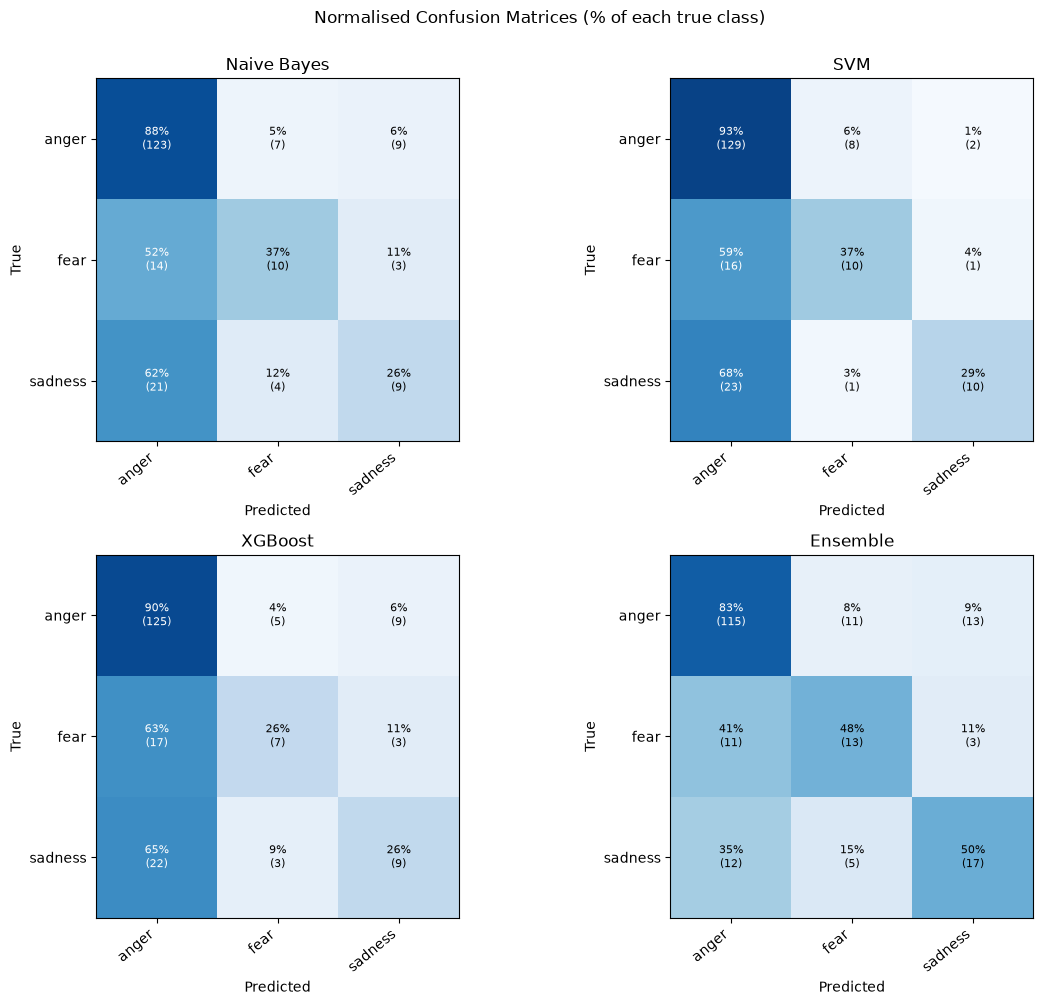

In [20]:
# ---- 8.3 Row-normalised confusion matrices (recall view) for all models ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p, labels=list(range(K)))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.suptitle("Normalised Confusion Matrices (% of each true class)", y=1.00)
plt.tight_layout(); save_fig("confusion_matrices_normalised"); plt.show()

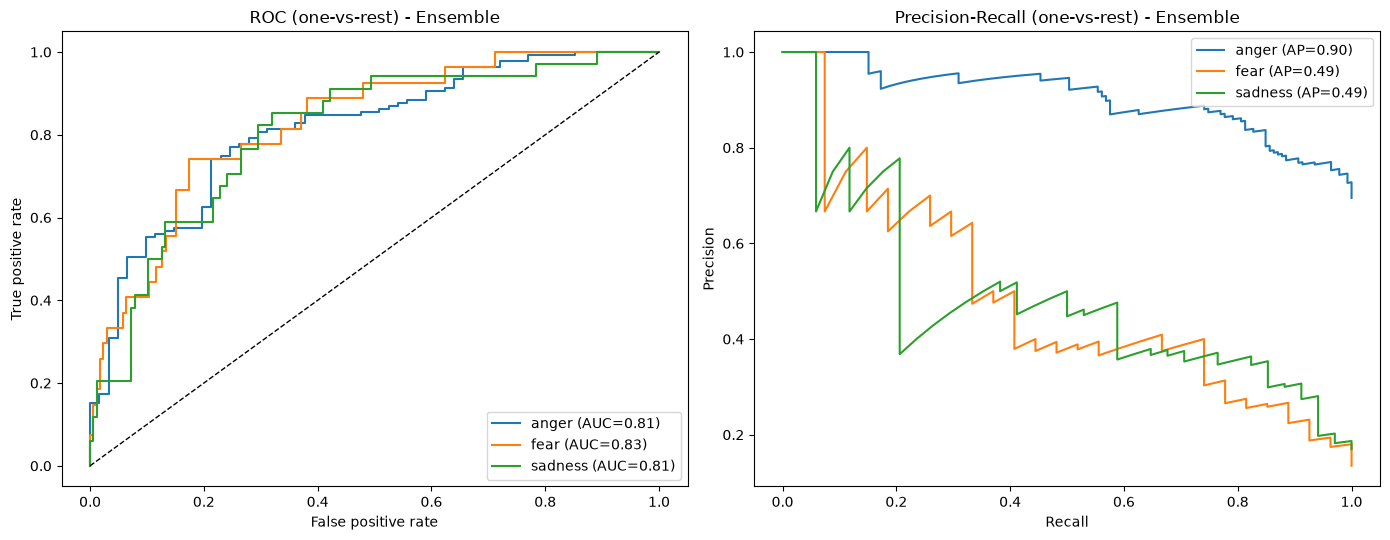

In [21]:
# ---- 8.4 ROC and Precision-Recall curves (one-vs-rest, Ensemble) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba_ens[:, i])
    ax1.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], proba_ens[:, i])
    ax2.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test_bin[:, i], proba_ens[:, i]):.2f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest) - Ensemble")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (one-vs-rest) - Ensemble")
ax1.legend(loc="lower right"); ax2.legend(loc="upper right")
plt.tight_layout(); save_fig("roc_pr_ensemble"); plt.show()

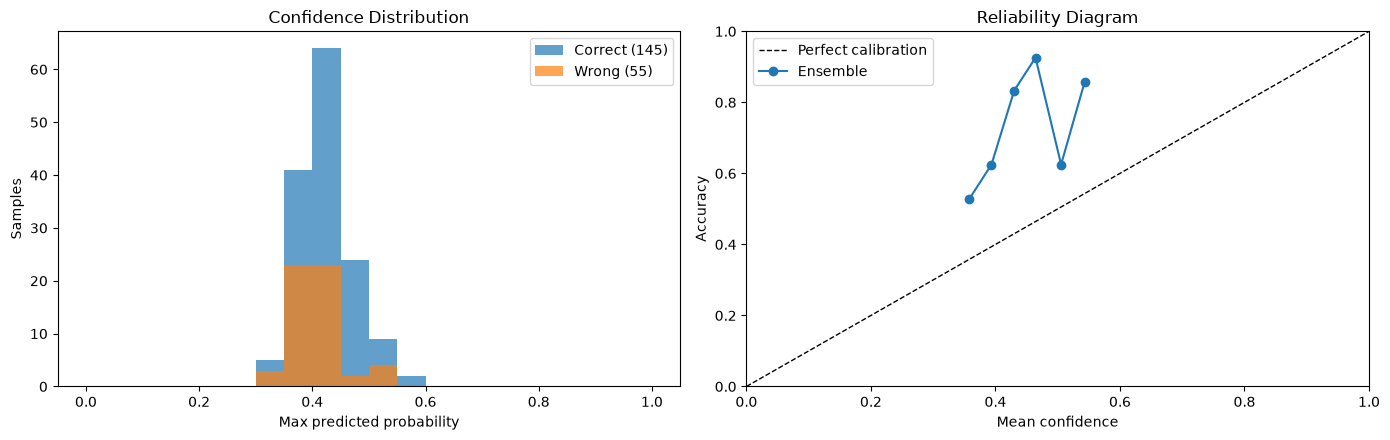

In [22]:
# ---- 8.5 Confidence: correct vs wrong predictions (Ensemble) ----
conf = proba_ens.max(axis=1)
correct = (y_pred_ens == y_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(0, 1, 21)
ax1.hist(conf[correct],  bins=bins, alpha=0.7, label=f"Correct ({correct.sum()})")
ax1.hist(conf[~correct], bins=bins, alpha=0.7, label=f"Wrong ({(~correct).sum()})")
ax1.set(xlabel="Max predicted probability", ylabel="Samples", title="Confidence Distribution")
ax1.legend()

# Reliability: accuracy per confidence bin
edges = np.linspace(conf.min(), conf.max(), 7)
idx = np.digitize(conf, edges[1:-1])
bin_acc  = [correct[idx == b].mean() if (idx == b).any() else np.nan for b in range(6)]
bin_conf = [conf[idx == b].mean()    if (idx == b).any() else np.nan for b in range(6)]
ax2.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax2.plot(bin_conf, bin_acc, "o-", label="Ensemble")
ax2.set(xlabel="Mean confidence", ylabel="Accuracy", title="Reliability Diagram", xlim=(0, 1), ylim=(0, 1))
ax2.legend()
plt.tight_layout(); save_fig("confidence_analysis"); plt.show()

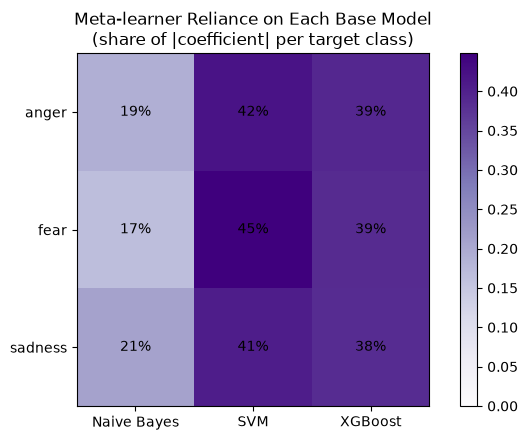

In [23]:
# ---- 8.6 Which base model does the meta-learner trust, per class? ----
# meta_learner.coef_ has shape (K, 3*K): [NB probs | SVM probs | XGB probs]
coef = meta_learner.coef_
base_names = ["Naive Bayes", "SVM", "XGBoost"]
weight = np.array([[np.abs(coef[c, b*K:(b+1)*K]).sum() for b in range(3)] for c in range(K)])
weight = weight / weight.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(weight, cmap="Purples", vmin=0, vmax=weight.max())
ax.set_xticks(range(3)); ax.set_xticklabels(base_names)
ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
for i in range(K):
    for j in range(3):
        ax.text(j, i, f"{weight[i, j]:.0%}", ha="center", va="center")
ax.set_title("Meta-learner Reliance on Each Base Model\n(share of |coefficient| per target class)")
plt.colorbar(im, ax=ax); plt.tight_layout(); save_fig("meta_learner_weights"); plt.show()

## 8.7 Top Terms Pushing Towards Each Class (all models + stacked model)

| Model | How the "push" towards a class is measured |
|---|---|
| **Naive Bayes** | `log P(term \| class)` minus the mean `log P(term \| other classes)` |
| **SVM** | Linear SVM coefficients per class (averaged over the calibration folds) |
| **XGBoost** | Mean signed TreeSHAP contribution (`pred_contribs`) of the term to that class's score, averaged over the training documents that contain the term (terms in fewer than 3 documents are ignored) |
| **Stacked ensemble** | Occlusion test: remove the term from a document and measure how much the *final stacked* probability of the class drops (the stack only sees base-model probabilities, so it has no coefficients per term) |

In [24]:
TOP = 12
TERM_SCORES = {}      # model name -> (vocab, scores of shape (K, n_terms)); used for the side-by-side table below

def plot_top_terms(vocab, scores, title, fname, top=TOP, xlabel="Score"):
    """For each class, bar-plot the `top` terms with the highest score (= pushing towards that class)."""
    fig, axes = plt.subplots(1, K, figsize=(3.8 * K, 5))
    for i, ax in enumerate(np.atleast_1d(axes)):
        idx = np.argsort(scores[i])[-top:]
        ax.barh(vocab[idx], scores[i][idx], color=f"C{i}")
        ax.set_title(CLASS_NAMES[i]); ax.set_xlabel(xlabel)
    plt.suptitle(title, y=1.02)
    plt.tight_layout(); save_fig(fname); plt.show()

def top_terms_table(vocab, scores, top=10):
    return pd.DataFrame({CLASS_NAMES[i]: vocab[np.argsort(scores[i])[::-1][:top]] for i in range(K)},
                        index=range(1, top + 1))

### 8.7.1 Naive Bayes

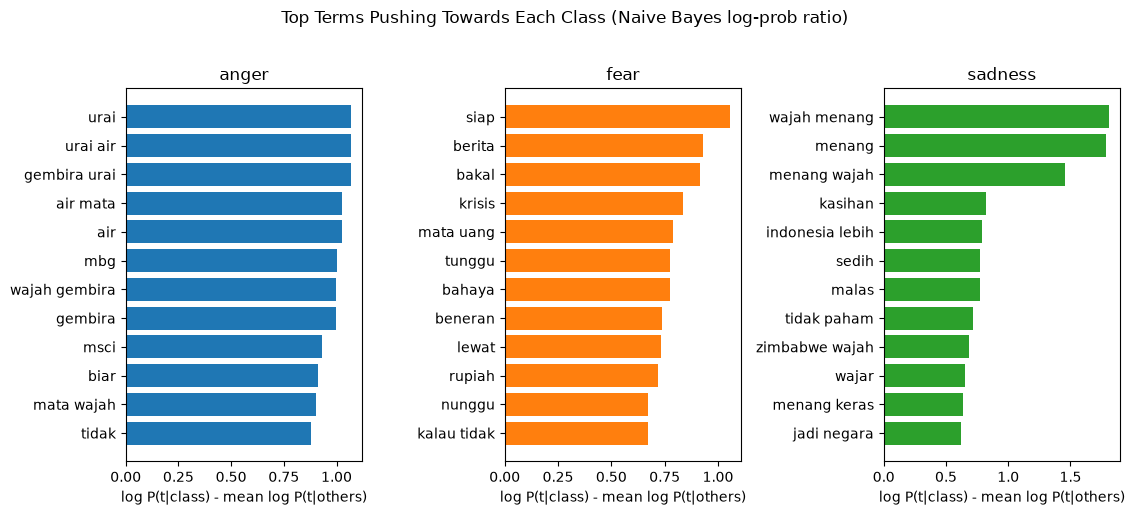

,anger,fear,sadness
1,urai,siap,wajah menang
2,urai air,berita,menang
3,gembira urai,bakal,menang wajah
4,air mata,krisis,kasihan
5,air,mata uang,indonesia lebih
6,mbg,tunggu,sedih
7,wajah gembira,bahaya,malas
8,gembira,beneran,tidak paham
9,msci,lewat,zimbabwe wajah
10,biar,rupiah,wajar


In [25]:
nb_vocab = np.array(nb_model.named_steps["tfidf"].get_feature_names_out())
flp = nb_model.named_steps["clf"].feature_log_prob_                      # (K, n_features)
nb_scores = np.vstack([flp[i] - np.delete(flp, i, axis=0).mean(axis=0) for i in range(K)])

TERM_SCORES["Naive Bayes"] = (nb_vocab, nb_scores)
plot_top_terms(nb_vocab, nb_scores, "Top Terms Pushing Towards Each Class (Naive Bayes log-prob ratio)",
               "nb_top_terms", xlabel="log P(t|class) - mean log P(t|others)")
display(top_terms_table(nb_vocab, nb_scores))

### 8.7.2 SVM

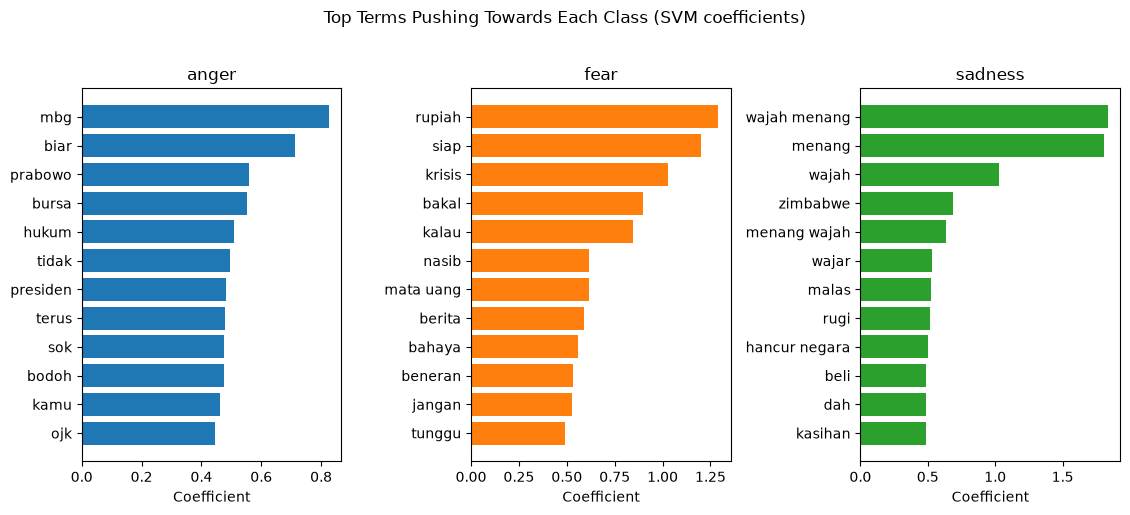

,anger,fear,sadness
1,mbg,rupiah,wajah menang
2,biar,siap,menang
3,prabowo,krisis,wajah
4,bursa,bakal,zimbabwe
5,hukum,kalau,menang wajah
6,tidak,nasib,wajar
7,presiden,mata uang,malas
8,terus,berita,rugi
9,sok,bahaya,hancur negara
10,bodoh,beneran,beli


In [26]:
svm_tfidf = svm_model.named_steps["tfidf"]
svm_vocab = np.array(svm_tfidf.get_feature_names_out())
cal = svm_model.named_steps["clf"]
coefs = []
for cc in cal.calibrated_classifiers_:
    est = getattr(cc, "estimator", None)
    if est is None:
        est = cc.base_estimator
    coefs.append(est.coef_)
svm_coef = np.mean(coefs, axis=0)           # (K, n_features)

TERM_SCORES["SVM"] = (svm_vocab, svm_coef)
plot_top_terms(svm_vocab, svm_coef, "Top Terms Pushing Towards Each Class (SVM coefficients)",
               "svm_top_terms", xlabel="Coefficient")
display(top_terms_table(svm_vocab, svm_coef))

### 8.7.3 XGBoost

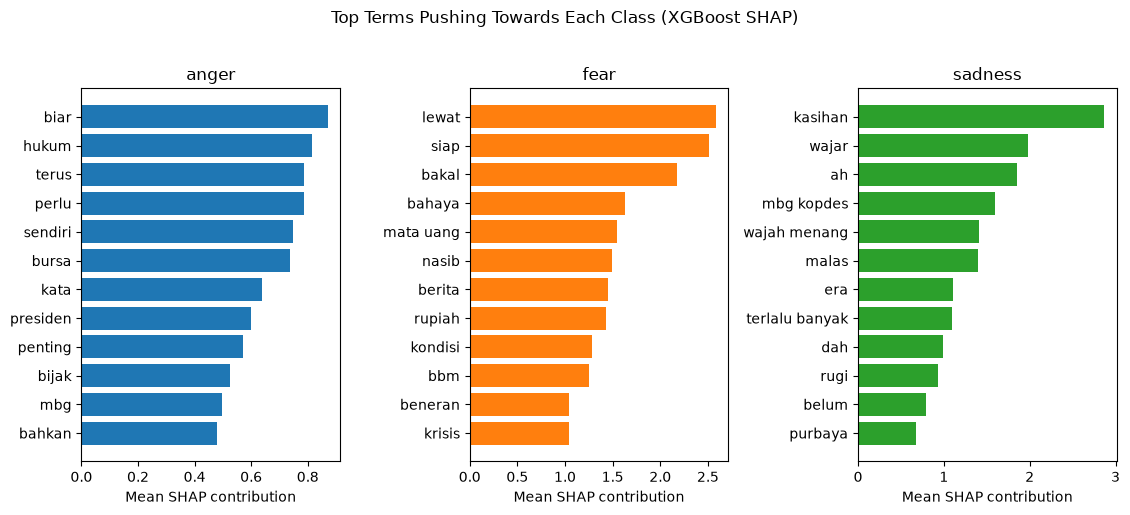

,anger,fear,sadness
1,biar,lewat,kasihan
2,hukum,siap,wajar
3,terus,bakal,ah
4,perlu,bahaya,mbg kopdes
5,sendiri,mata uang,wajah menang
6,bursa,nasib,malas
7,kata,berita,era
8,presiden,rupiah,terlalu banyak
9,penting,kondisi,dah
10,bijak,bbm,rugi


In [27]:
import xgboost as xgb

xgb_tfidf = xgb_model.named_steps["tfidf"]
xgb_vocab = np.array(xgb_tfidf.get_feature_names_out())
booster   = xgb_model.named_steps["clf"].get_booster()

# TreeSHAP: per-document, per-class, per-feature contributions to the class score (last column = bias)
Xtr_tfidf  = xgb_tfidf.transform(X_train)
contribs   = booster.predict(xgb.DMatrix(Xtr_tfidf), pred_contribs=True)[:, :, :-1]   # (n, K, n_features)

# average only over documents that actually contain the term (same idea as coef * tfidf for the linear models)
present    = (Xtr_tfidf > 0).toarray().astype(float)                     # (n, n_features)
doc_count  = present.sum(axis=0)
xgb_scores = (contribs * present[:, None, :]).sum(axis=0) / np.maximum(doc_count, 1)   # (K, n_features)
xgb_scores[:, doc_count < 3] = xgb_scores.min()                          # ignore terms seen in < 3 documents

TERM_SCORES["XGBoost"] = (xgb_vocab, xgb_scores)
plot_top_terms(xgb_vocab, xgb_scores, "Top Terms Pushing Towards Each Class (XGBoost SHAP)",
               "xgb_top_terms", xlabel="Mean SHAP contribution")
display(top_terms_table(xgb_vocab, xgb_scores))

### 8.7.4 Stacked Ensemble (occlusion)

The meta-learner only sees base-model probabilities, so term effects are measured end-to-end: for every candidate term,
take the documents that contain it, delete it, re-run the **whole stack** (NB + SVM + XGB -> meta-learner) and record
`P(class | original) - P(class | term removed)`. A positive value means the term pushes the stack towards that class.

* Candidates = union of the top terms of the three base models (keeps the run fast).
* Documents = train + test pooled (probabilities on the training set alone are over-confident for XGBoost/SVM).
* Terms that appear in fewer than `MIN_DOCS` documents are skipped (too noisy).

207 candidate terms evaluated on 1000 documents (8,512 occlusions)


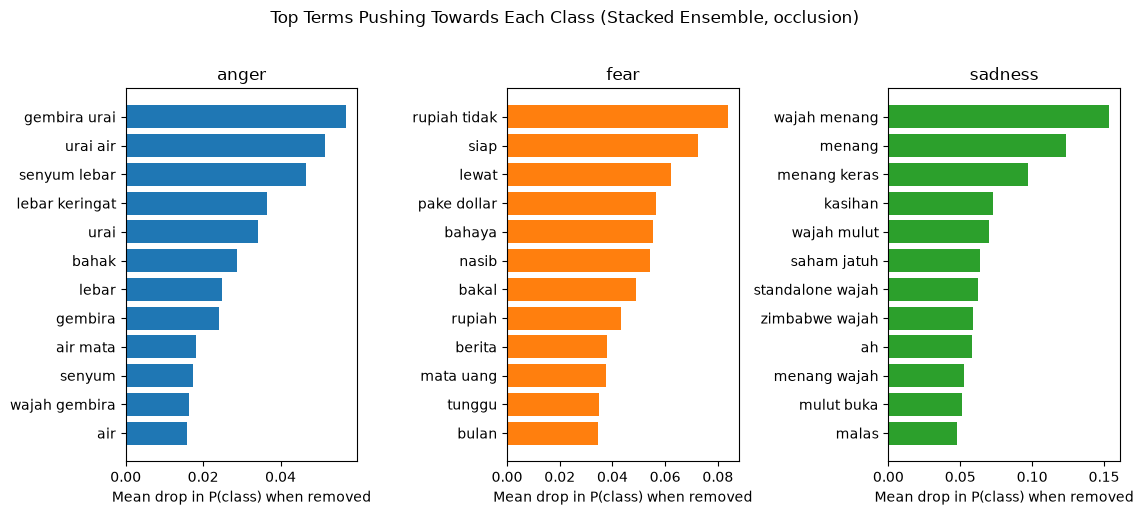

,anger,fear,sadness
1,gembira urai,rupiah tidak,wajah menang
2,urai air,siap,menang
3,senyum lebar,lewat,menang keras
4,lebar keringat,pake dollar,kasihan
5,urai,bahaya,wajah mulut
6,bahak,nasib,saham jatuh
7,lebar,bakal,standalone wajah
8,gembira,rupiah,zimbabwe wajah
9,air mata,berita,ah
10,senyum,mata uang,menang wajah


In [28]:
import re

CAND_PER_CLASS = 40
MIN_DOCS = 3

def stack_predict_proba(texts):
    """Full stacking pipeline: raw text -> base-model probabilities -> meta-learner probabilities."""
    texts = np.asarray(texts, dtype=object)
    meta = np.hstack([nb_model.predict_proba(texts),
                      svm_model.predict_proba(texts),
                      xgb_model.predict_proba(texts)])
    return meta_learner.predict_proba(meta)

# candidate terms = top terms (per class) of every base model
candidates = sorted({
    str(w)
    for vocab_, sc_ in TERM_SCORES.values()
    for i in range(K)
    for w in vocab_[np.argsort(sc_[i])[-CAND_PER_CLASS:]]
})

all_texts = np.array([str(t) for t in np.concatenate([X_train, X_test])], dtype=object)
base_p    = stack_predict_proba(all_texts)                               # (N, K)

# build every "term removed" document once, predict in a single batch
mod_texts, owner_term, owner_doc = [], [], []
for t_idx, term in enumerate(candidates):
    rx   = re.compile(rf"(?<!\S){re.escape(term)}(?!\S)")
    hits = [d for d, txt in enumerate(all_texts) if rx.search(txt)]
    if len(hits) < MIN_DOCS:
        continue
    for d in hits:
        mod_texts.append(rx.sub(" ", all_texts[d]))
        owner_term.append(t_idx); owner_doc.append(d)

new_p       = stack_predict_proba(mod_texts)
owner_term  = np.array(owner_term); owner_doc = np.array(owner_doc)
delta       = base_p[owner_doc] - new_p                                  # drop in P(class) when the term is removed

used_terms  = np.unique(owner_term)
stack_vocab = np.array([candidates[t] for t in used_terms])
stack_scores = np.vstack([
    [delta[owner_term == t, c].mean() for t in used_terms] for c in range(K)
])                                                                       # (K, n_used_terms)

print(f"{len(stack_vocab)} candidate terms evaluated on {len(all_texts)} documents ({len(mod_texts):,} occlusions)")
TERM_SCORES["Stacked Ensemble"] = (stack_vocab, stack_scores)
plot_top_terms(stack_vocab, stack_scores, "Top Terms Pushing Towards Each Class (Stacked Ensemble, occlusion)",
               "stack_top_terms", xlabel="Mean drop in P(class) when removed")
display(top_terms_table(stack_vocab, stack_scores))

### 8.7.5 Side-by-side comparison (top 8 terms per class and model)

In [29]:
side = {}
for model_name, (vocab_, sc_) in TERM_SCORES.items():
    for i in range(K):
        side[(CLASS_NAMES[i], model_name)] = vocab_[np.argsort(sc_[i])[::-1][:8]]
side_df = pd.DataFrame(side, index=range(1, 9))
side_df = side_df.reindex(columns=pd.MultiIndex.from_tuples(side_df.columns))
display(side_df)

,anger,fear,sadness,anger,fear,sadness,anger,fear,sadness,anger,fear,sadness
,Naive Bayes,Naive Bayes,Naive Bayes,SVM,SVM,SVM,XGBoost,XGBoost,XGBoost,Stacked Ensemble,Stacked Ensemble,Stacked Ensemble
1,urai,siap,wajah menang,mbg,rupiah,wajah menang,biar,lewat,kasihan,gembira urai,rupiah tidak,wajah menang
2,urai air,berita,menang,biar,siap,menang,hukum,siap,wajar,urai air,siap,menang
3,gembira urai,bakal,menang wajah,prabowo,krisis,wajah,terus,bakal,ah,senyum lebar,lewat,menang keras
4,air mata,krisis,kasihan,bursa,bakal,zimbabwe,perlu,bahaya,mbg kopdes,lebar keringat,pake dollar,kasihan
5,air,mata uang,indonesia lebih,hukum,kalau,menang wajah,sendiri,mata uang,wajah menang,urai,bahaya,wajah mulut
6,mbg,tunggu,sedih,tidak,nasib,wajar,bursa,nasib,malas,bahak,nasib,saham jatuh
7,wajah gembira,bahaya,malas,presiden,mata uang,malas,kata,berita,era,lebar,bakal,standalone wajah
8,gembira,beneran,tidak paham,terus,berita,rugi,presiden,rupiah,terlalu banyak,gembira,rupiah,zimbabwe wajah


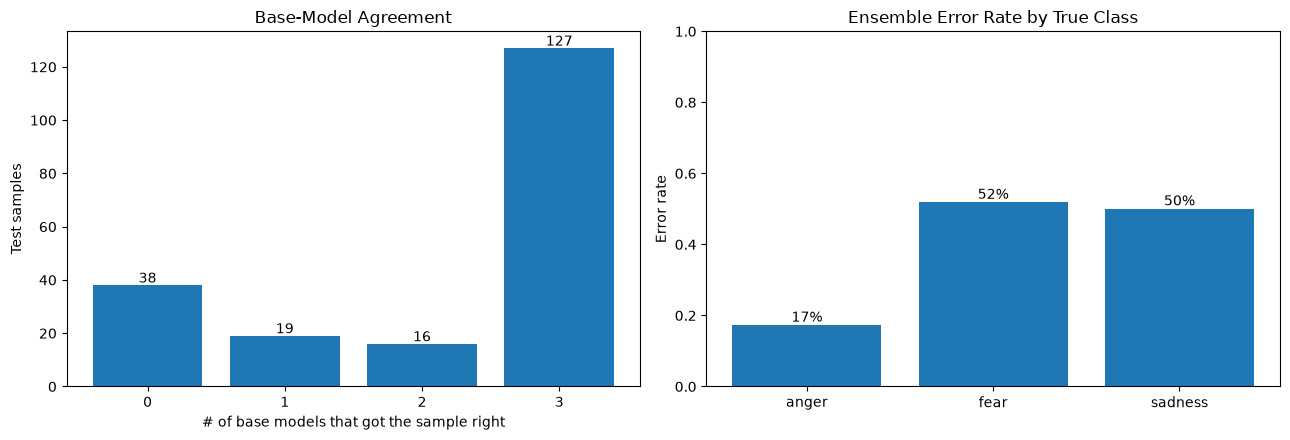

,text,true,pred,confidence
160,tuhann lindung indonesia bangkrut hancur ekonomi lipat tangan wajah menang wajah menang,fear,sadness,0.550
65,ambruk ambles monopoly krisis percaya party popper krisis yakin pasar saham,sadness,fear,0.514
156,punya saham sih komen cuma nongki sama aja sama asing tulis tahu negara kok andal asing warga negara asing enak piki...,anger,sadness,0.508
35,lhoo bilang orang desa tidak pake dollar kerja dapat lapor jadi tanya tahu tidak yaa beliau kondisi aktual negeri,anger,fear,0.501
107,tuh catat tanggal yakin perintah tidak bakal kerja bahkan peduli buat ngerjain pr msci lalu rupiah anljok otomatis h...,anger,fear,0.485
121,pak presiden kalau mau ngasi diskon saham pikir wajah senyum lebar keringat ujung ujung gantung antek asing,sadness,anger,0.452
150,kia tidak daya tawar buat insvestor asing karna semua number daya milik perintah cuma beberapa persen aja proyek con...,sadness,anger,0.446
196,tidak bakal kerjain pr nya tuju hyper inflasi woohoo,anger,fear,0.438
67,baru pertama kali gua takut wajah senyum lebar keringat soal ada ekonomi indonesia,fear,anger,0.436
43,rasa nya rakyat konoha rela tara zimbabwe hancur rezim fir aun sombong munta ampun,anger,fear,0.429


In [30]:
# ---- 8.8 Model agreement & error analysis ----
base_correct = np.vstack([
    (y_pred_nb  == y_test),
    (y_pred_svm == y_test),
    (y_pred_xgb == y_test),
]).sum(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
vals = np.bincount(base_correct, minlength=4)
ax1.bar(range(4), vals)
for i, v in enumerate(vals):
    ax1.text(i, v + 1, str(v), ha="center")
ax1.set_xticks(range(4)); ax1.set_xlabel("# of base models that got the sample right")
ax1.set_ylabel("Test samples"); ax1.set_title("Base-Model Agreement")

# Error rate per true class (Ensemble)
err_rate = [(y_pred_ens[y_test == i] != i).mean() for i in range(K)]
ax2.bar(CLASS_NAMES, err_rate)
for i, v in enumerate(err_rate):
    ax2.text(i, v + 0.01, f"{v:.0%}", ha="center")
ax2.set_ylim(0, 1); ax2.set_ylabel("Error rate"); ax2.set_title("Ensemble Error Rate by True Class")
plt.tight_layout(); save_fig("agreement_and_errors"); plt.show()

# Most confident mistakes -> worth reading manually (label noise? ambiguous text?)
err_df = pd.DataFrame({
    "text":       texts_test,
    "true":       [CLASS_NAMES[i] for i in y_test],
    "pred":       [CLASS_NAMES[i] for i in y_pred_ens],
    "confidence": conf.round(3),
})
err_df = err_df[err_df["true"] != err_df["pred"]].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 120)
err_df.head(15)